# 03 - SSB on the interlaced acquisition, across dose

**C10 = 0, 30 mrad, 0.10 A scan step.** Zero defocus because SSB assumes it *knows* the
aberration phase rather than solving for it; at the 00 block's C10 = 100 A, chi wraps
1.85 pi across the aperture and the two sidebands interfere through $e^{2i\chi}$ instead
of adding.

For every dose, three reconstructions:

| | input | what it should be |
|---|---|---|
| **base SSB** | light-off cube | the static structure |
| **excited SSB - base SSB** | both cubes | $\Delta\varphi$ the crude way: two full scans, so twice the dose |
| **excitation SSB** | the interlaced cube | $\Delta\varphi$ from **one** scan, by demodulating the carrier |

The third is the method. The second is the baseline it has to justify itself against, and
it is not a fair fight in the method's favour - it costs two scans and does not exist as
an experiment, because the real acquisition interlaces the two states at *different* scan
positions.

## Why this notebook does not call `DirectPtychography`

At this geometry one datacube is **13.3 GB**, and the route through
`Dataset4d` / `DirectPtychography` holds four copies of it at once - the memory-mapped
pages, the interlaced output, `apply_poisson_dose`'s page-locked staging buffer, and its
output copy - before quanTEM adds a shifted tensor and a
$(N_{\rm BF}, N_Q, N_Q)$ corrected stack. Measured peak: **62 GB of RSS before the
reconstruction even starts**, which OOM-kills the machine.

So the virtual bright-field stack is built in scan-row blocks straight off the
memory-mapped noiseless files (`method_wrappers.build_vbf_stack`), and only that stack -
$N_{\rm BF}\times N_Q^2$ floats, 3.4 GB rather than 13.3 - is ever resident. Peak RSS is
about 29 GB, most of it reclaimable page cache.

## The algorithm

`method_wrappers.ssb_accumulate` forms the three sums over bright-field pixels that SSB
needs, from $G(\mathbf Q,\mathbf k) = i\tilde\varphi(\mathbf Q)\Gamma(\mathbf k,\mathbf Q)$
with

$$\Gamma(\mathbf k,\mathbf Q)=A(\mathbf k)\bigl[A(\mathbf k-\mathbf Q)-A(\mathbf k+\mathbf Q)\bigr]$$

**Notebook `03.4` derives this and carries a readable inline copy** - go there to
understand it. Here it is wired for memory and swept over dose.

One structural consequence worth knowing before reading on: the accumulation is done
**once per (dose, cube)**, and every estimator variant below is just a different division
of the same three sums. So the expensive cell runs once and the whole extensions section
afterwards is free.

**Outputs** `results/03_dose_*.npz` (+ `.json`), `results/03_extensions.json`


In [1]:
%load_ext autoreload
%autoreload 2

import json
import gc
import sys
import time
from pathlib import Path

import numpy as np
import torch
import matplotlib.pyplot as plt
from scipy.ndimage import map_coordinates

NOTEBOOK_DIR = Path.cwd()
DATA_DIR = NOTEBOOK_DIR / "data"
RESULTS_DIR = NOTEBOOK_DIR / "results"
RESULTS_DIR.mkdir(exist_ok=True)
sys.path.insert(0, str(NOTEBOOK_DIR.parent))
import method_wrappers as mw
from quantem.core import config

config.set_device(0)


def rss_gb():
    for line in open("/proc/self/status"):
        if line.startswith("VmRSS:"):
            return int(line.split()[1]) / 1e6
    return float("nan")


# ---- the dataset this notebook owns ---------------------------------------------
OVERRIDES = {"defocus_C10_ang": 0.0, "convergence_semiangle_mrad": 30.0, "step_ang": 0.1}
PREFIX = "focus0_s010"
# ---------------------------------------------------------------------------------

with open(DATA_DIR / "ideal_geometry.json") as handle:
    BASE_META = json.load(handle)
BASE_PATH, EXC_PATH, META = mw.ensure_dataset(DATA_DIR, BASE_META, OVERRIDES, prefix=PREFIX)

LAM        = META["beam"]["wavelength_ang"]
ALPHA_MRAD = META["beam"]["convergence_semiangle_mrad"]
scan_step  = META["scan"]["step_ang"]
n_scan     = META["scan"]["n_positions_per_side"]
object_dx  = META["cell"]["dx_ang"]
n_object   = META["cell"]["n_pixels"]
object_x   = (np.arange(n_object) - n_object // 2) * object_dx
F_NY       = 1.0 / (2 * scan_step)
BANDWIDTH  = META["probe"]["bandwidth_inv_ang"]

# memory-mapped; never fully materialised
src_off = np.load(BASE_PATH, mmap_mode="r")
src_on = np.load(EXC_PATH, mmap_mode="r")

truth = np.load(DATA_DIR / "ideal_truth.npz")
delta_phi_true = truth["delta_phi_true"].astype(np.float64)

print(f"scan      : {n_scan}^2 at {scan_step} A over {META['scan']['extent_ang']} A")
print(f"f_Nyquist : {F_NY:.4f} 1/A vs bandwidth {BANDWIDTH:.4f} 1/A "
      f"({F_NY/BANDWIDTH:.2f}x oversampled - the carrier is cleanly separated)")
print(f"cubes     : {src_off.shape}, {src_off.nbytes/1e9:.1f} GB each (memory-mapped)")
print(f"truth     : peak |delta phi| = {np.abs(delta_phi_true).max():.5f} rad, "
      f"base phase spans {np.ptp(truth['phase_base']):.5f} rad")
print(f"RSS now   : {rss_gb():.1f} GB")


cuda:0
  cached: focus0_s010_base_noiseless.npy, focus0_s010_excited_noiseless.npy  (C10 0.0 A, 30.0 mrad, 300^2 at 0.1 A)
scan      : 300^2 at 0.1 A over 30.0 A
f_Nyquist : 5.0000 1/A vs bandwidth 1.2330 1/A (4.06x oversampled - the carrier is cleanly separated)
cubes     : (300, 300, 192, 192), 13.3 GB each (memory-mapped)
truth     : peak |delta phi| = 0.02106 rad, base phase spans 0.23433 rad
RSS now   : 0.9 GB


## Detector geometry, measured from the data

The bright-field mask, the beam centre and the detector scale all come out of the mean
diffraction pattern, which is itself accumulated in scan-row blocks. The disc radius
follows from the mask's area, and that radius **is** $\alpha$ by definition - which is
what sets $\Delta k$.


In [2]:
t0 = time.time()
mean_dp = mw.mean_diffraction_pattern(src_off)
bf_mask, (c_i, c_j), mrad_per_px, dk, k_cut, KX, KY = mw.bright_field_geometry(
    mean_dp, ALPHA_MRAD, LAM)
num_bf = int(bf_mask.sum())
bf_kx, bf_ky = KX[bf_mask], KY[bf_mask]

print(f"BF disc   : {num_bf:,} px, centre ({c_i:.3f}, {c_j:.3f}), "
      f"R = {np.sqrt(num_bf/np.pi):.2f} px")
print(f"scale     : {mrad_per_px:.6f} mrad/px -> dk = {dk:.5f} 1/A")
print(f"aperture  : k_cut = {k_cut:.4f} 1/A, bandwidth 2*k_cut = {2*k_cut:.4f} 1/A")
print(f"vBF stack : {n_scan}x{n_scan}x{num_bf} float32 = "
      f"{n_scan*n_scan*num_bf*4/1e9:.2f} GB (vs {src_off.nbytes/1e9:.1f} GB for the cube)")
print(f"({time.time()-t0:.0f} s, RSS {rss_gb():.1f} GB)")


BF disc   : 9,401 px, centre (96.000, 96.003), R = 54.70 px
scale     : 0.548415 mrad/px -> dk = 0.01127 1/A
aperture  : k_cut = 0.6165 1/A, bandwidth 2*k_cut = 1.2330 1/A
vBF stack : 300x300x9401 float32 = 3.38 GB (vs 13.3 GB for the cube)
(3 s, RSS 13.9 GB)


## Scoring

Everything is resampled onto one physical grid and scored the same way. Fit a single
scale $s=\langle t,r\rangle/\langle t,t\rangle$, then:

* **scale** - 1.0 means the amplitude is right. This has to work at **infinite dose**
  before any dose sweep means anything.
* **rho** - Pearson correlation: shape, amplitude divided out.
* **nrmse** - $\lVert r-t\rVert/\lVert t\rVert$, unforgiving about both.

`snr` is **deliberately not a headline**. It divides by the per-pixel residual standard
deviation, which assumes a white residual over all $N_{\rm pix}$ degrees of freedom; a
band-limited residual has only $\sim\pi Q_{\max}^2/\Delta Q^2$ of them, so the metric is
inflated by $\sqrt{N_{\rm pix}/M}$ - around 20x at $Q_{\max}=0.15$ and 1x without a band
limit. The inflation depends on the variant, so `snr` cannot rank these rows against each
other. It is carried with its inflation factor printed beside it, as a warning.


In [3]:
def to_grid(a, px, axis):
    ax = (np.arange(a.shape[0]) - a.shape[0] / 2 + 0.5) * px
    co = (axis - ax[0]) / px
    gy, gx = np.meshgrid(co, co, indexing="ij")
    return map_coordinates(a.astype(np.float64), np.vstack([gy.ravel(), gx.ravel()]),
                           order=1, mode="nearest").reshape(gy.shape)

_half = min(n_scan / 2 * scan_step, object_x[-1]) * 0.98
AXIS = np.arange(-_half, _half + 1e-9, object_dx)
TRUTH = to_grid(delta_phi_true, object_dx, AXIS)
TRUTH -= TRUTH.mean()
dQ = 1.0 / (n_scan * scan_step)
print(f"common grid {TRUTH.shape} at {object_dx:.5f} A, +/-{_half:.2f} A, "
      f"peak {np.abs(TRUTH).max():.5f} rad;  dQ = {dQ:.4f} 1/A")


def score(d, q_max=None, px=None):
    """px defaults to this notebook's scan step; pass it for a different scan grid.
    Getting it wrong misregisters the reconstruction against the truth."""
    r = to_grid(d, scan_step if px is None else px, AXIS); r = r - r.mean()
    s = float(np.vdot(TRUTH, r).real) / float(np.vdot(TRUTH, TRUTH).real)
    res = r - s * TRUTH
    dq_here = dQ if px is None else 1.0 / (d.shape[0] * px)
    n_eff = r.size if q_max is None else max(np.pi * (q_max / dq_here) ** 2, 1.0)
    return dict(scale=s,
                rho=float(np.corrcoef(r.ravel(), TRUTH.ravel())[0, 1]),
                nrmse=float(np.linalg.norm(r - TRUTH) / np.linalg.norm(TRUTH)),
                snr=float(abs(s) * np.linalg.norm(TRUTH) / res.std()),
                snr_inflation=float(np.sqrt(r.size / n_eff)))


def print_scores(rows, title):
    print(f"\n{title}")
    print(f"{'dose':>6s} {'variant':<34s} {'peak':>9s} {'scale':>8s} {'rho':>8s} "
          f"{'nrmse':>8s} {'snr':>9s} {'infl':>7s}")
    print("-" * 95)
    for r in rows:
        print(f"{r['dose']:>6s} {r['variant']:<34s} {r['peak']:9.5f} {r['scale']:8.4f} "
              f"{r['rho']:8.4f} {r['nrmse']:8.4f} {r['snr']:9.1f} "
              f"{r['snr_inflation']:6.1f}x")
    print("-" * 95)


common grid (298, 298) at 0.09892 A, +/-14.70 A, peak 0.02099 rad;  dQ = 0.0333 1/A


## Parameters


In [4]:
# ---- the dose ladder ------------------------------------------------------------
DOSES = [None, 1e7, 1e6, 1e5]        # None = infinite; 1e6 is the dose we are after
SEED = 0                             # pin the Poisson draws
# ...but give every (dataset, dose) its OWN stream. Reusing one seed across the three
# datasets makes the light-off and light-on cubes share a noise realisation, so
# "excited SSB - base SSB" cancels its own shot noise and scores ~the same at 1e5 as at
# infinite dose. That is not a two-scan experiment, it is a bookkeeping artefact.
SEED_STREAM = {"base": 0, "excited": 10_000, "interlaced": 20_000}
ROWS = 16                            # scan rows per streaming block (a memory knob)
CHUNK = 256                          # bright-field pixels per GPU batch (a memory knob)
# ---------------------------------------------------------------------------------

def dose_label(d):
    return "inf" if d is None else f"{d:.0e}"

print(f"{len(DOSES)} doses: " + ", ".join(dose_label(d) for d in DOSES))
print("electrons per position: " + ", ".join(
    "inf" if d is None else f"{d*scan_step**2:,.0f}" for d in DOSES))


4 doses: inf, 1e+07, 1e+06, 1e+05
electrons per position: inf, 100,000, 10,000, 1,000


## The one expensive cell

Three stacks per dose - light-off, light-on, interlaced - each built, accumulated and
thrown away before the next. What survives is the accumulation: five $(N_Q, N_Q)$ tensors
per cube, about 4 MB, so all twelve fit in 50 MB and **everything after this cell is
instant**.

The carrier channel is accumulated for the single-state cubes too. It has no business
being there - they are not interlaced - so it is the control: whatever it returns is the
noise floor of the demodulation.


In [5]:
ACC = {}
t_all = time.time()
for dose in DOSES:
    lab = dose_label(dose)
    ACC[lab] = {}
    for name, (a, b) in (("base", (src_off, None)),
                         ("excited", (src_on, None)),
                         ("interlaced", (src_off, src_on))):
        t0 = time.time()
        seed = SEED + SEED_STREAM[name] + 1_000_000 * DOSES.index(dose)
        vbf = mw.build_vbf_stack(a, b, bf_mask, dose, scan_step, rows=ROWS, seed=seed)
        ACC[lab][name] = mw.ssb_accumulate(vbf, bf_kx, bf_ky, scan_step, k_cut, dk,
                                           chunk=CHUNK)
        del vbf
        gc.collect(); torch.cuda.empty_cache()
        print(f"  dose {lab:>6s}  {name:<11s} {time.time()-t0:5.0f} s   "
              f"RSS {rss_gb():5.1f} GB")
print(f"\ntotal {time.time()-t_all:.0f} s")


  dose    inf  base           14 s   RSS  15.7 GB


  dose    inf  excited        14 s   RSS  28.7 GB


  dose    inf  interlaced     14 s   RSS  28.7 GB


  dose  1e+07  base           14 s   RSS  28.8 GB


  dose  1e+07  excited        13 s   RSS  28.8 GB


  dose  1e+07  interlaced     14 s   RSS  28.8 GB


... (2 outputs left out)

  dose  1e+06  interlaced     14 s   RSS  28.8 GB


  dose  1e+05  base           14 s   RSS  28.8 GB


  dose  1e+05  excited        14 s   RSS  28.8 GB


  dose  1e+05  interlaced     14 s   RSS  28.8 GB

total 167 s


## The three reconstructions

`matched=False` is quanTEM's estimator exactly: the phase-only kernel $\Gamma/|\Gamma|$
averaged flat over every bright-field pixel. That is the MVP, and it is what the figure
below shows.


In [6]:
MVP = {}
MVP_ROWS = []
for dose in DOSES:
    lab = dose_label(dose)
    base_obj = mw.ssb_invert(ACC[lab]["base"], matched=False, channel="struct")
    exc_obj = mw.ssb_invert(ACC[lab]["excited"], matched=False, channel="struct")
    d_int, Obar = mw.excitation_phase(ACC[lab]["interlaced"], matched=False)
    base_ph = np.angle(base_obj.cpu().numpy())
    exc_ph = np.angle(exc_obj.cpu().numpy())
    MVP[lab] = dict(base=base_ph, excited=exc_ph, sub=exc_ph - base_ph,
                    direct=d_int, mean_object_phase=np.angle(Obar))
    for variant, img in (("excited SSB - base SSB", exc_ph - base_ph),
                         ("direct SSB (interlaced)", d_int)):
        m = score(img)
        m.update(dose=lab, variant=variant, peak=float(np.abs(img).max()))
        MVP_ROWS.append(m)

print_scores(MVP_ROWS, "MVP (quanTEM's estimator), scored against the truth")
print("scale 1.0 = correct amplitude. A dose sweep of a method whose scale is already\n"
      "wrong at infinite dose is measuring its transfer function, not the dose.")



MVP (quanTEM's estimator), scored against the truth
  dose variant                                 peak    scale      rho    nrmse       snr    infl
-----------------------------------------------------------------------------------------------
   inf excited SSB - base SSB               0.00752   0.1807   0.8827   0.8249     559.8    1.0x
   inf direct SSB (interlaced)              0.00752   0.1807   0.8827   0.8249     559.8    1.0x
 1e+07 excited SSB - base SSB               0.00725   0.1758   0.5105   0.8758     176.9    1.0x
 1e+07 direct SSB (interlaced)              0.00715   0.1783   0.4058   0.9146     132.3    1.0x
 1e+06 excited SSB - base SSB               0.00807   0.1717   0.1930   1.2032      58.6    1.0x
 1e+06 direct SSB (interlaced)              0.01330   0.1733   0.1375   1.4973      41.4    1.0x
 1e+05 excited SSB - base SSB               0.02406   0.1623   0.0589   2.8765      17.6    1.0x
 1e+05 direct SSB (interlaced)              0.03743   0.2028   0.0510   4.0

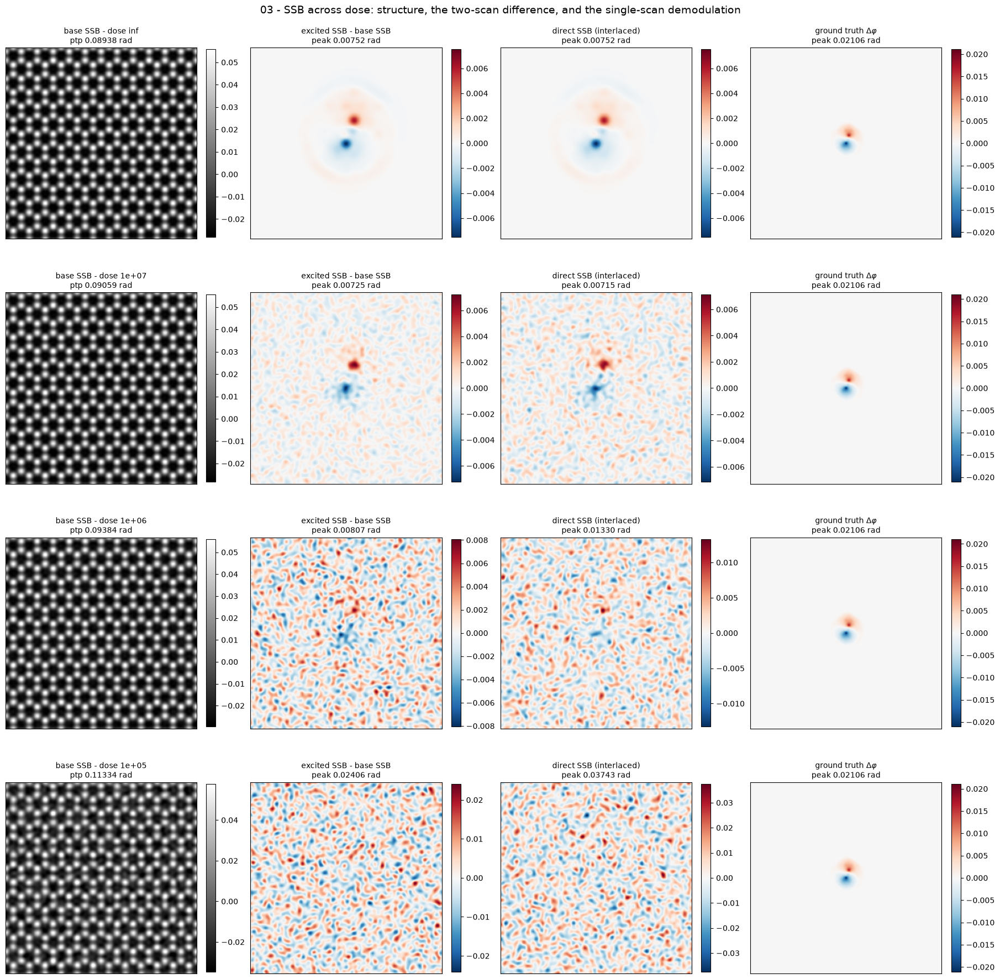

In [7]:
n_rows = len(DOSES)
fig, axes = plt.subplots(n_rows, 4, figsize=(18.0, 4.5 * n_rows),
                         constrained_layout=True, squeeze=False)
for row, dose in enumerate(DOSES):
    lab = dose_label(dose)
    r = MVP[lab]
    lo, hi = np.percentile(r["base"], [0.5, 99.5])
    ax = axes[row][0]
    im = ax.imshow(r["base"].T, origin="lower", cmap="gray", vmin=lo, vmax=hi)
    ax.set_title(f"base SSB - dose {lab}\nptp {np.ptp(r['base']):.5f} rad", fontsize=10)
    fig.colorbar(im, ax=ax, shrink=0.8)
    for col, (name, img) in enumerate(
            (("excited SSB - base SSB", r["sub"]),
             ("direct SSB (interlaced)", r["direct"]),
             (r"ground truth $\Delta\varphi$", delta_phi_true)), start=1):
        lim = float(np.abs(img).max()) or 1e-12
        ax = axes[row][col]
        im = ax.imshow(img.T, origin="lower", cmap="RdBu_r", vmin=-lim, vmax=lim)
        ax.set_title(f"{name}\npeak {lim:.5f} rad", fontsize=10)
        fig.colorbar(im, ax=ax, shrink=0.8)
    for ax in axes[row]:
        ax.set_xticks([]); ax.set_yticks([])
fig.suptitle("03 - SSB across dose: structure, the two-scan difference, and the "
             "single-scan demodulation", fontsize=14)
plt.show()


In [8]:
for dose in DOSES:
    lab = dose_label(dose)
    r = MVP[lab]
    path = RESULTS_DIR / f"03_dose_{lab}.npz"
    np.savez_compressed(path, delta_phi=r["direct"], phase_base=r["base"],
                        phase_excited=r["excited"],
                        mean_object_phase=r["mean_object_phase"],
                        pixel_size_ang=np.asarray(scan_step, dtype=float))
    with open(path.with_suffix(".json"), "w") as handle:
        json.dump(dict(method="03", dose=lab, prefix=PREFIX, overrides=OVERRIDES,
                       scan_step_ang=scan_step, n_scan=n_scan, num_bf=num_bf,
                       pixel_size_ang=scan_step,
                       scores=[m for m in MVP_ROWS if m["dose"] == lab]),
                  handle, indent=2)
    print("wrote", path.name, "+", path.with_suffix(".json").name)


wrote 03_dose_inf.npz + 03_dose_inf.json
wrote 03_dose_1e+07.npz + 03_dose_1e+07.json
wrote 03_dose_1e+06.npz + 03_dose_1e+06.json
wrote 03_dose_1e+05.npz + 03_dose_1e+05.json


---

# Extensions to the MVP

The MVP loses most of the amplitude **before any noise is involved**, so these are judged
at infinite dose first and only then across dose.

Why it loses it: with the phase-only kernel the estimator's transfer function is exactly

$$f(Q)=\frac{1}{N_{\rm BF}}\sum_k|\Gamma(\mathbf k,\mathbf Q)|
=\frac{\text{trotter area}}{\text{BF disc area}}$$

which **peaks at 0.80 near $Q=0.55\ \mathrm{\AA^{-1}}$ and falls to 0.07 at 0.03**. It is a
band-pass that suppresses the band a smooth excitation lives in while passing the
signal-free mid-band at nearly unity. Three changes:

**(1) $\Gamma$-matched inversion.** Weight by $\Gamma$ instead of normalising it away and
divide by what actually contributed:
$\hat O=\sum_k\Gamma^{*}G/(\sum_k|\Gamma|^{2}+\lambda)$. This is the least-squares solution
of the forward model and fixes the **amplitude**.

**(2) Band-limit** the carrier channel to $|Q|<Q_{\max}$. A prior, and the one the
proposal already argues: excitation-induced redistribution is smoother than the static
potential. 95% of this $\Delta\varphi$'s energy is below $0.15\ \mathrm{\AA^{-1}}$. This
is what carries the **finite-dose** gain.

**(3) Stabilised readout**, $2\,\mathrm{Im}(\mathrm dO\,\bar O^{*})/\max(|\bar O|^2,\varepsilon)$
instead of $2\arctan\mathrm{Im}(\mathrm dO/\bar O)$, to avoid dividing by a noisy $\bar O$.

(1) and (2) are **independent and both needed**; the four corners below show that. (3) was
expected to matter and does not - it is kept because a negative result measured is worth
more than one assumed.

All of this reuses the accumulations from above. Nothing is rebuilt.


In [9]:
# ---- extension knobs ------------------------------------------------------------
Q_MAX = 0.15          # 1/A, band limit on the carrier channel
LAM_REL = 1e-5        # ridge, relative to max(den); flat over 1e-6 .. 1e-3
# ---------------------------------------------------------------------------------

VARIANTS = {
    "MVP (flat mean)":        dict(matched=False, q_max=None),
    f"+band Q<{Q_MAX}":       dict(matched=False, q_max=Q_MAX),
    "+matched":               dict(matched=True,  q_max=None),
    f"+matched +band Q<{Q_MAX}": dict(matched=True, q_max=Q_MAX),
}

EXT, EXT_ROWS = {}, []
for dose in DOSES:
    lab = dose_label(dose)
    for name, kw in VARIANTS.items():
        d, _ = mw.excitation_phase(ACC[lab]["interlaced"], lam_rel=LAM_REL, **kw)
        EXT[(lab, name)] = d
        m = score(d, kw["q_max"])
        m.update(dose=lab, variant=name, peak=float(np.abs(d).max()))
        EXT_ROWS.append(m)

print_scores(EXT_ROWS, "extensions, scored against the truth")


def two_scan_delta(acc_b, acc_e, matched, q_max):
    """excited - base through the SAME estimator: reconstruct and subtract.

    The band limit goes on the DIFFERENCE, not on each object -- band-limiting the
    objects themselves would throw the lattice away, which is not what is being asked.
    """
    ob_b = mw.ssb_invert(acc_b, matched=matched, lam_rel=LAM_REL)
    ob_e = mw.ssb_invert(acc_e, matched=matched, lam_rel=LAM_REL)
    d = np.angle(ob_e.cpu().numpy()) - np.angle(ob_b.cpu().numpy())
    if q_max is not None:
        qr = acc_b["QR"].cpu().numpy()
        D = np.fft.fft2(d)
        D[qr > q_max] = 0
        d = np.real(np.fft.ifft2(D))
    return d


# The two-scan difference is only a fair yardstick if it gets the same estimator. With
# the MVP on both sides it inherits the same crippled transfer function, which makes the
# single-scan method look better than it is.
TWO_SCAN = {"2-scan, MVP estimator": dict(matched=False, q_max=None),
            f"2-scan, matched+band Q<{Q_MAX}": dict(matched=True, q_max=Q_MAX)}
TWO_SCAN_ROWS = []
for dose in DOSES:
    lab = dose_label(dose)
    for name, kw in TWO_SCAN.items():
        d = two_scan_delta(ACC[lab]["base"], ACC[lab]["excited"], **kw)
        m = score(d, kw["q_max"])
        m.update(dose=lab, variant=name, peak=float(np.abs(d).max()))
        TWO_SCAN_ROWS.append(m)

print_scores(TWO_SCAN_ROWS, "the two-scan difference, same estimators (2x the dose)")



extensions, scored against the truth
  dose variant                                 peak    scale      rho    nrmse       snr    infl
-----------------------------------------------------------------------------------------------
   inf MVP (flat mean)                      0.00752   0.1807   0.8827   0.8249     559.8    1.0x
   inf +band Q<0.15                         0.00239   0.1557   0.9199   0.8469     699.1   37.4x
   inf +matched                             0.02022   0.9676   0.9993   0.0492    7788.2    1.0x
   inf +matched +band Q<0.15                0.01230   0.9180   0.9734   0.2313    1265.1   37.4x
 1e+07 MVP (flat mean)                      0.00715   0.1783   0.4058   0.9146     132.3    1.0x
 1e+07 +band Q<0.15                         0.00235   0.1541   0.8898   0.8496     581.1   37.4x
 1e+07 +matched                             0.09324   0.9436   0.0982   9.5675      29.4    1.0x
 1e+07 +matched +band Q<0.15                0.01196   0.8961   0.9529   0.3035     936.4  

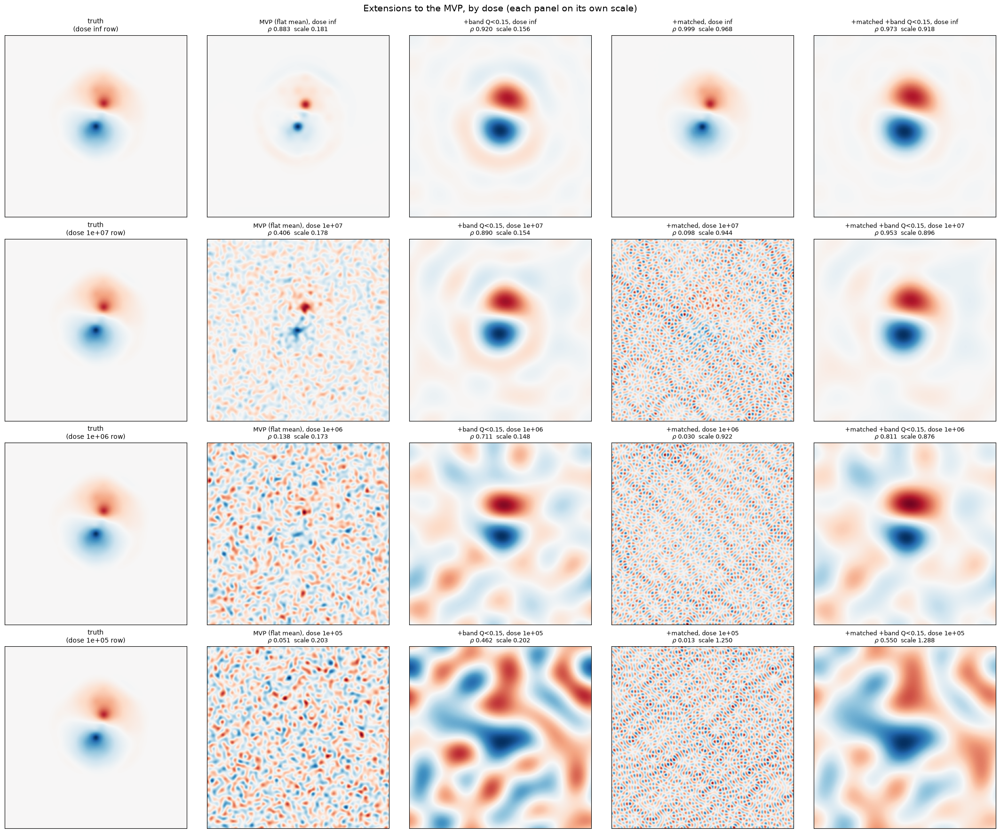

In [10]:
n_rows, n_cols = len(DOSES), len(VARIANTS) + 1
fig, axes = plt.subplots(n_rows, n_cols, figsize=(4.3 * n_cols, 4.4 * n_rows),
                         constrained_layout=True, squeeze=False)
lim_t = float(np.abs(TRUTH).max())
for row, dose in enumerate(DOSES):
    lab = dose_label(dose)
    axes[row][0].imshow(TRUTH.T, origin="lower", cmap="RdBu_r", vmin=-lim_t, vmax=lim_t)
    axes[row][0].set_title(f"truth\n(dose {lab} row)", fontsize=10)
    for col, name in enumerate(VARIANTS, start=1):
        d = EXT[(lab, name)]
        m = next(x for x in EXT_ROWS if x["dose"] == lab and x["variant"] == name)
        lim = float(np.abs(d).max()) or 1e-12
        axes[row][col].imshow(d.T, origin="lower", cmap="RdBu_r", vmin=-lim, vmax=lim)
        axes[row][col].set_title(f"{name}, dose {lab}\n" + r"$\rho$ " +
                                 f"{m['rho']:.3f}  scale {m['scale']:.3f}", fontsize=9)
    for ax in axes[row]:
        ax.set_xticks([]); ax.set_yticks([])
fig.suptitle("Extensions to the MVP, by dose (each panel on its own scale)", fontsize=14)
plt.show()


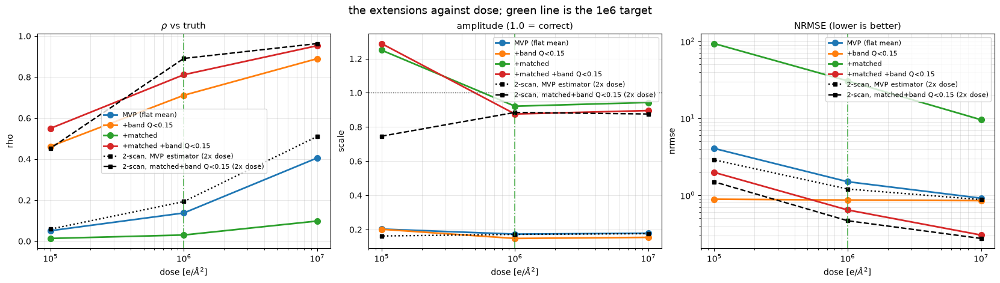

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(16.5, 4.6), constrained_layout=True)
finite = [d for d in DOSES if d is not None]
for key, ax, ttl in (("rho", axes[0], r"$\rho$ vs truth"),
                     ("scale", axes[1], "amplitude (1.0 = correct)"),
                     ("nrmse", axes[2], "NRMSE (lower is better)")):
    for name in VARIANTS:
        ys = [next(r[key] for r in EXT_ROWS
                   if r["dose"] == dose_label(d) and r["variant"] == name) for d in finite]
        ax.plot(finite, ys, "o-", lw=2.0, ms=7, label=name)
    for ts_name, style in zip(TWO_SCAN, ("k:", "k--")):
        ys = [next(r[key] for r in TWO_SCAN_ROWS
                   if r["dose"] == dose_label(d) and r["variant"] == ts_name)
              for d in finite]
        ax.plot(finite, ys, style, lw=1.7, marker="s", ms=5, label=ts_name + " (2x dose)")
    ax.set_xscale("log")
    if key == "nrmse":
        ax.set_yscale("log")
    if key == "scale":
        ax.axhline(1.0, color="#444", ls=":", lw=1.0)
    ax.axvline(1e6, color="#2ca02c", lw=1.4, ls="-.", alpha=0.7)
    ax.set_xlabel(r"dose [e/$\AA^2$]"); ax.set_ylabel(key)
    ax.set_title(ttl, fontsize=11); ax.grid(alpha=0.3, which="both"); ax.legend(fontsize=8)
fig.suptitle("the extensions against dose; green line is the 1e6 target", fontsize=13)
plt.show()


## How sharp is $Q_{\max}$, and does the readout matter?

Both free, since the accumulations are already in hand.


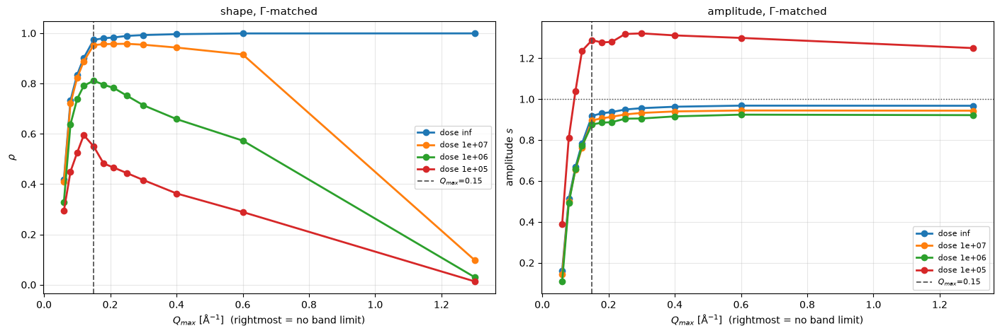

  dose    inf: best rho 0.9993 at Q_max = None
  dose  1e+07: best rho 0.9578 at Q_max = 0.25
  dose  1e+06: best rho 0.8115 at Q_max = 0.15
  dose  1e+05: best rho 0.5948 at Q_max = 0.12

readout check, matched + band, every dose:
  dose    inf: arctan rho 0.973363   stable rho 0.973363   naive rho 0.973363   
  dose  1e+07: arctan rho 0.952914   stable rho 0.952914   naive rho 0.952914   
  dose  1e+06: arctan rho 0.811460   stable rho 0.811462   naive rho 0.811462   
  dose  1e+05: arctan rho 0.549875   stable rho 0.549878   naive rho 0.549879   

wrote 03_extensions.json


In [12]:
QS = [0.06, 0.08, 0.10, 0.12, 0.15, 0.18, 0.21, 0.25, 0.30, 0.40, 0.60, None]
fig, axes = plt.subplots(1, 2, figsize=(14.0, 4.6), constrained_layout=True)
xs = [q if q is not None else 1.3 for q in QS]
sweep_rows = []
for dose in DOSES:
    lab = dose_label(dose)
    rho_m, sc_m = [], []
    for qm in QS:
        d, _ = mw.excitation_phase(ACC[lab]["interlaced"], matched=True,
                                   lam_rel=LAM_REL, q_max=qm)
        m = score(d, qm); m.update(dose=lab, q_max=qm)
        sweep_rows.append(m)
        rho_m.append(m["rho"]); sc_m.append(m["scale"])
    axes[0].plot(xs, rho_m, "o-", lw=2.0, ms=6, label=f"dose {lab}")
    axes[1].plot(xs, sc_m, "o-", lw=2.0, ms=6, label=f"dose {lab}")
for ax, ylab, ttl in ((axes[0], r"$\rho$", "shape"),
                      (axes[1], "amplitude $s$", "amplitude")):
    ax.axvline(Q_MAX, color="#555", ls="--", lw=1.3, label=f"$Q_{{max}}$={Q_MAX}")
    ax.set_xlabel(r"$Q_{max}$ [$\mathrm{\AA^{-1}}$]  (rightmost = no band limit)")
    ax.set_ylabel(ylab); ax.set_title(f"{ttl}, $\\Gamma$-matched", fontsize=11)
    ax.grid(alpha=0.3); ax.legend(fontsize=8)
axes[1].axhline(1.0, color="#444", ls=":", lw=1.0)
plt.show()

for dose in DOSES:
    lab = dose_label(dose)
    best = max((r for r in sweep_rows if r["dose"] == lab), key=lambda r: r["rho"])
    print(f"  dose {lab:>6s}: best rho {best['rho']:.4f} at Q_max = {best['q_max']}")

print("\nreadout check, matched + band, every dose:")
read_rows = []
for dose in DOSES:
    lab = dose_label(dose)
    line = f"  dose {lab:>6s}: "
    for ro in ("arctan", "stable", "naive"):
        d, _ = mw.excitation_phase(ACC[lab]["interlaced"], matched=True,
                                   lam_rel=LAM_REL, q_max=Q_MAX, readout=ro)
        m = score(d, Q_MAX); m.update(dose=lab, readout=ro); read_rows.append(m)
        line += f"{ro} rho {m['rho']:.6f}   "
    print(line)

with open(RESULTS_DIR / "03_extensions.json", "w") as handle:
    json.dump(dict(prefix=PREFIX, overrides=OVERRIDES, q_max=Q_MAX, lam_rel=LAM_REL,
                   seed=SEED, num_bf=num_bf, mvp=MVP_ROWS, extensions=EXT_ROWS,
                   two_scan=TWO_SCAN_ROWS, q_sweep=sweep_rows, readout=read_rows),
              handle, indent=2, default=str)
print("\nwrote 03_extensions.json")


---

# Reconstruct and subtract, at the same total dose

Everything above demodulates **one** interlaced scan. The alternative is the obvious one:
scan twice, reconstruct each state separately, subtract. This section applies the same
four estimators to that, under a matched electron budget, so the two acquisition schemes
can be compared rather than just the estimators.

## The dose accounting

Dose is quoted in $e/\mathrm{\AA}^2$, and $e/\mathrm{\AA}^2 \times$ area is the electron
count **regardless of scan step**. So a total budget of $10^6$ split across two scans is
$5\times10^5$ each, and all three schemes below deposit $9\times10^8$ electrons over the
30 A field. Every row of every figure holds the total fixed; only how those electrons are
spread changes.

## Why two step sizes

In the interlaced scan each state only occupies a checkerboard **sublattice**, so its
per-state sampling is $\Delta\sqrt2$, not $\Delta$. Two separate scans at the same
$\Delta$ sample each state more finely than that; at $2\Delta$, more coarsely. The
interlaced case is bracketed:

| scheme | step | positions | per state | effective per-state step | $e$/position |
|---|---|---|---|---|---|
| interlaced | 0.10 | 90,000 | 45,000 | **0.1414 A** | 10,000 |
| R&S | 0.10 | 180,000 | 90,000 | 0.1000 A | 5,000 |
| R&S | 0.20 | 45,000 | 22,500 | 0.2000 A | 20,000 |

(at a $10^6$ total; the $e$/position column is per scan.)

That is the comparison worth making - not "is subtraction better", which it trivially can
be given a free second scan, but **what the interlacing costs in sampling** once the
electrons are held fixed. One figure per step size, rows by total dose, directly
comparable to the extensions figure above.

The 0.20 A dataset is simulated on first run by `ensure_dataset` and cached after.


In [13]:
# ---- the comparison ------------------------------------------------------------
RS_STEPS = [0.10, 0.20]            # per-scan step; 0.10 matches the interlaced grid
RS_DOSES = [None, 1e7, 1e6, 1e5]   # TOTAL dose; each of the two scans gets half
# ---------------------------------------------------------------------------------

RS, RS_ROWS = {}, []
for step_rs in RS_STEPS:
    ov = dict(OVERRIDES); ov["step_ang"] = step_rs
    prefix_rs = f"focus0_s{int(round(step_rs * 100)):03d}"
    print(f"\n=== reconstruct & subtract, step {step_rs} A ===")
    bp, ep, meta_rs = mw.ensure_dataset(DATA_DIR, BASE_META, ov, prefix=prefix_rs)
    off_rs = np.load(bp, mmap_mode="r")
    on_rs = np.load(ep, mmap_mode="r")
    n_rs = meta_rs["scan"]["n_positions_per_side"]

    # The detector and probe are untouched, so this should reproduce the geometry
    # measured at the top -- recomputed rather than assumed, because silently reusing a
    # k-grid from a different dataset is exactly the kind of error that looks like physics.
    mdp_rs = mw.mean_diffraction_pattern(off_rs)
    bf_rs, c_rs, mpp_rs, dk_rs, kcut_rs, KX_rs, KY_rs = mw.bright_field_geometry(
        mdp_rs, ALPHA_MRAD, LAM)
    print(f"  {n_rs}^2 positions, num_bf {int(bf_rs.sum()):,} "
          f"(top of notebook: {num_bf:,}), dk {dk_rs:.5f} (vs {dk:.5f})")

    for dose_total in RS_DOSES:
        lab = dose_label(dose_total)
        half = None if dose_total is None else dose_total / 2
        t0 = time.time()
        accs = {}
        for nm, src in (("base", off_rs), ("excited", on_rs)):
            vbf = mw.build_vbf_stack(src, None, bf_rs, half, step_rs, rows=ROWS,
                                     seed=SEED + SEED_STREAM[nm]
                                     + 1_000_000 * RS_DOSES.index(dose_total)
                                     + 7_000_000 * RS_STEPS.index(step_rs))
            accs[nm] = mw.ssb_accumulate(vbf, KX_rs[bf_rs], KY_rs[bf_rs], step_rs,
                                        kcut_rs, dk_rs, chunk=CHUNK, carrier=False)
            del vbf
            gc.collect(); torch.cuda.empty_cache()
        for name, kw in VARIANTS.items():
            d = two_scan_delta(accs["base"], accs["excited"], **kw)
            RS[(step_rs, lab, name)] = d
            m = score(d, kw["q_max"], px=step_rs)
            m.update(step=step_rs, dose=lab, variant=name, peak=float(np.abs(d).max()))
            RS_ROWS.append(m)
        del accs
        gc.collect(); torch.cuda.empty_cache()
        print(f"  dose {lab:>6s} (2 x {dose_label(half)}): "
              f"{time.time()-t0:4.0f} s   RSS {rss_gb():5.1f} GB")



=== reconstruct & subtract, step 0.1 A ===
  cached: focus0_s010_base_noiseless.npy, focus0_s010_excited_noiseless.npy  (C10 0.0 A, 30.0 mrad, 300^2 at 0.1 A)


  300^2 positions, num_bf 9,401 (top of notebook: 9,401), dk 0.01127 (vs 0.01127)


  dose    inf (2 x inf):   28 s   RSS  54.9 GB


  dose  1e+07 (2 x 5e+06):   27 s   RSS  54.9 GB


  dose  1e+06 (2 x 5e+05):   27 s   RSS  54.9 GB


  dose  1e+05 (2 x 5e+04):   27 s   RSS  54.9 GB

=== reconstruct & subtract, step 0.2 A ===


... (3 outputs left out)

  dose    inf (2 x inf):    6 s   RSS  36.5 GB


  dose  1e+07 (2 x 5e+06):    6 s   RSS  36.5 GB


  dose  1e+06 (2 x 5e+05):    6 s   RSS  36.5 GB


  dose  1e+05 (2 x 5e+04):    6 s   RSS  36.5 GB


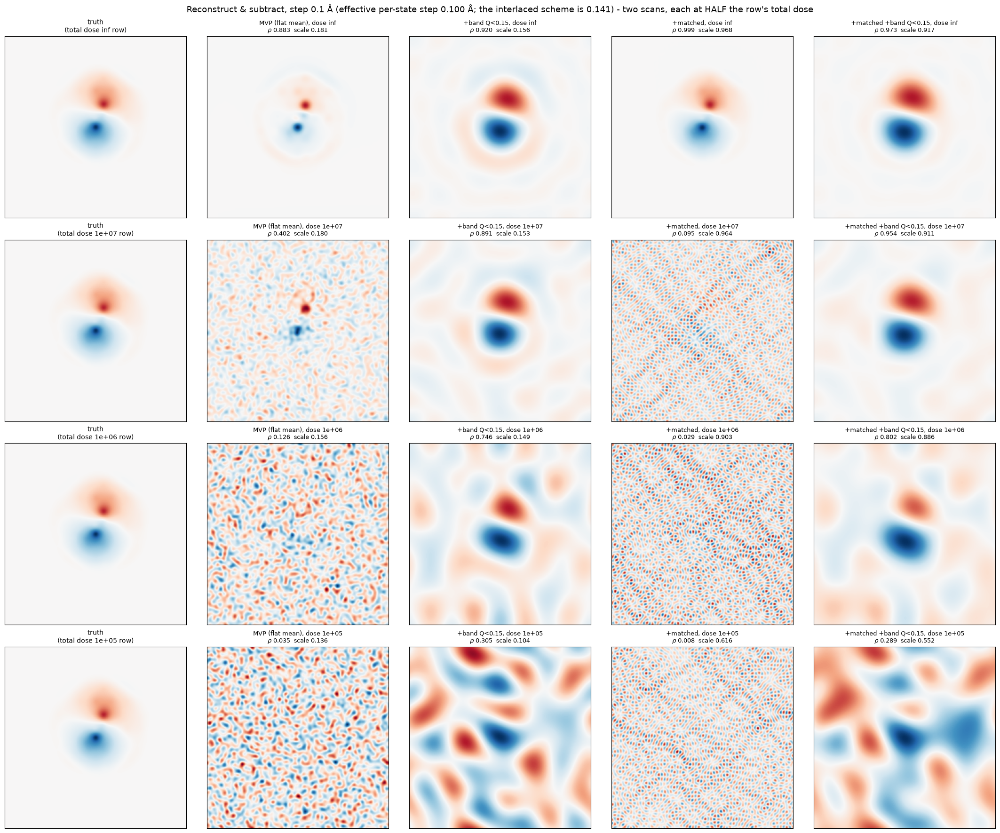

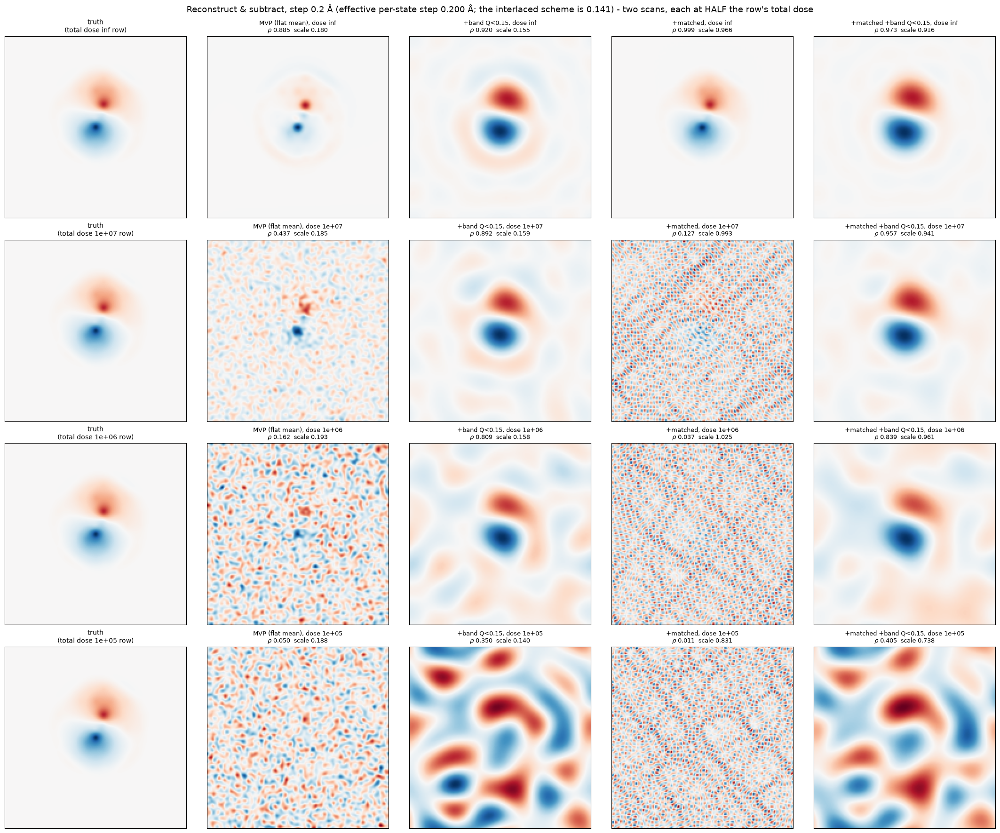

In [14]:
for step_rs in RS_STEPS:
    n_cols = len(VARIANTS) + 1
    fig, axes = plt.subplots(len(RS_DOSES), n_cols,
                             figsize=(4.3 * n_cols, 4.4 * len(RS_DOSES)),
                             constrained_layout=True, squeeze=False)
    for row, dose_total in enumerate(RS_DOSES):
        lab = dose_label(dose_total)
        axes[row][0].imshow(TRUTH.T, origin="lower", cmap="RdBu_r",
                            vmin=-lim_t, vmax=lim_t)
        axes[row][0].set_title(f"truth\n(total dose {lab} row)", fontsize=10)
        for col, name in enumerate(VARIANTS, start=1):
            d = RS[(step_rs, lab, name)]
            m = next(x for x in RS_ROWS if x["step"] == step_rs
                     and x["dose"] == lab and x["variant"] == name)
            l = float(np.abs(d).max()) or 1e-12
            axes[row][col].imshow(d.T, origin="lower", cmap="RdBu_r", vmin=-l, vmax=l)
            axes[row][col].set_title(f"{name}, dose {lab}\n" + r"$\rho$ " +
                                     f"{m['rho']:.3f}  scale {m['scale']:.3f}",
                                     fontsize=9)
        for ax in axes[row]:
            ax.set_xticks([]); ax.set_yticks([])
    eff = step_rs
    fig.suptitle(f"Reconstruct & subtract, step {step_rs} $\\mathrm{{\\AA}}$ "
                 f"(effective per-state step {eff:.3f} $\\mathrm{{\\AA}}$; the "
                 f"interlaced scheme is 0.141) - two scans, each at HALF the row's total "
                 f"dose", fontsize=13)
    plt.show()


In [15]:
print_scores(RS_ROWS, "reconstruct & subtract (2 scans at half dose each)")

print("\nSide by side at each total dose - one interlaced scan against two scans:")
print(f"{'dose':>6s} {'estimator':<26s} {'interlaced 0.141':>17s} "
      f"{'R&S 0.10':>10s} {'R&S 0.20':>10s}")
print("-" * 76)
for dose_total in RS_DOSES:
    lab = dose_label(dose_total)
    for name in VARIANTS:
        inter = next((r["rho"] for r in EXT_ROWS
                      if r["dose"] == lab and r["variant"] == name), float("nan"))
        cells = []
        for st in RS_STEPS:
            cells.append(next((r["rho"] for r in RS_ROWS if r["step"] == st
                               and r["dose"] == lab and r["variant"] == name),
                              float("nan")))
        print(f"{lab:>6s} {name:<26s} {inter:17.4f} "
              + "".join(f"{c:10.4f}" for c in cells))
print("-" * 76)
print("rho against the truth. Every column spends the same total electrons; the")
print("interlaced column does it in ONE scan and the other two in two.")

with open(RESULTS_DIR / "03_reconstruct_subtract.json", "w") as handle:
    json.dump(dict(prefix=PREFIX, overrides=OVERRIDES, q_max=Q_MAX, lam_rel=LAM_REL,
                   rs_steps=RS_STEPS, rs_doses=[dose_label(d) for d in RS_DOSES],
                   note="each of the two scans gets HALF the quoted total dose",
                   rows=RS_ROWS, interlaced=EXT_ROWS), handle, indent=2, default=str)
print("\nwrote 03_reconstruct_subtract.json")



reconstruct & subtract (2 scans at half dose each)
  dose variant                                 peak    scale      rho    nrmse       snr    infl
-----------------------------------------------------------------------------------------------
   inf MVP (flat mean)                      0.00752   0.1807   0.8827   0.8249     559.8    1.0x
   inf +band Q<0.15                         0.00238   0.1556   0.9199   0.8470     699.1   37.4x
   inf +matched                             0.02022   0.9676   0.9993   0.0492    7789.2    1.0x
   inf +matched +band Q<0.15                0.01228   0.9165   0.9734   0.2315    1265.2   37.4x
 1e+07 MVP (flat mean)                      0.00718   0.1795   0.4021   0.9167     130.9    1.0x
 1e+07 +band Q<0.15                         0.00237   0.1527   0.8912   0.8508     585.4   37.4x
 1e+07 +matched                             0.11225   0.9639   0.0946  10.1455      28.3    1.0x
 1e+07 +matched +band Q<0.15                0.01246   0.9110   0.9544   0.29

### Reading the comparison

Three things the figures are set up to separate:

* **Estimator vs acquisition.** All four columns are the same four estimators used on the
  interlaced data, so any difference between this section and the extensions figure is the
  *acquisition scheme*, not the reconstruction. The MVP column should be just as broken
  here as there - the transfer function $f(Q)$ does not care how the data was collected.
* **What the interlacing costs.** At $0.10\ \mathrm{\AA}$ the two scans sample each state
  more finely than the interlaced sublattice does, and at $0.20\ \mathrm{\AA}$ more
  coarsely. If the interlaced result sits between the two, the cost of interlacing is
  purely the halved sampling and nothing subtler. If it sits below both, interlacing is
  costing something else - which would be worth chasing.
* **What the second scan buys.** Reconstruct-and-subtract gets two independent
  measurements of the object, and the excitation is the difference of two large, nearly
  equal numbers - so its noise is the *sum* of both reconstructions'. Interlacing measures
  the difference directly at the carrier. Whether that trade favours one or the other at a
  fixed electron budget is precisely what these numbers answer, and it is the question the
  proposal needs settled.

One caveat that applies to all of it: reconstruct-and-subtract is not available in the
real experiment. The two scans would be separated in time, so drift, contamination and
dose history differ between them, none of which is simulated here. These numbers are the
*best case* for subtraction, and the interlaced scheme exists to avoid exactly those
errors. Block 1 of this study is where that gets tested.


## What to read off

1. **The `inf` row of the scale column, first.** The MVP's amplitude deficit at infinite
   dose is a property of the transfer function, not the dose. Only a variant that reaches
   scale $\approx 1$ and $\rho > 0.95$ with no noise has a dose curve worth reading.
2. **`+band` alone against `+matched` alone.** They fix different things - the band limit
   buys the shape, the matched weighting buys the amplitude - and neither is sufficient.
   `+matched` with no band limit is *worse* than the MVP at finite dose, because restoring
   the low-$Q$ amplitude restores the low-$Q$ noise with it.
3. **The single-scan result against the two black two-scan lines.** Both get twice the
   electrons and neither exists as an experiment - the real acquisition interlaces the
   two states at *different* scan positions. The dotted line is the two-scan difference
   through the MVP estimator and the dashed one is the same difference through
   `matched+band`; only the dashed one is a fair yardstick, because comparing a fixed
   method against a crippled baseline proves nothing. The method does not have to beat
   it, only come close enough that one scan is worth having.
4. **$Q_{\max}$ is a prior, not a fitted parameter.** The sweep here shows what it costs,
   but on real data it has to be set from what is being looked for. A sharp feature - a
   vacancy, say - would be cut by it, which is what the vacancy control in
   `backup/03x_20261021_163809/03.2_ssb_defects.ipynb` establishes.
